# 0_Importazione librerie

In [7]:
import torch
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt 
import seaborn as sns
import fastapi
import uvicorn
import streamlit
import openai

# 1_Caricamento del dataset

In [8]:
# definizione nome colonne
col_names = ['pregnant', 'glucose', 'bp', 'skin', 'insulin', 'bmi', 'pedigree', 'age', 'label']

# caricamento dataframe
df = pd.read_csv('pima-indians-diabetes.csv', names=col_names)

# Visualizziamo le prime 5 righe per capire la struttura
print("Prime righe del dataset:")
display(df.head())

# Informazioni generali (tipi di dati e valori non nulli)
print("\nInformazioni sul dataset:")
df.info()

# Controllo dei valori nulli per colonna
print("\nValori nulli per colonna:")
print(df.isnull().sum())

Prime righe del dataset:


,pregnant,glucose,bp,skin,insulin,bmi,pedigree,age,label
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Informazioni sul dataset:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   pregnant  768 non-null    int64  
 1   glucose   768 non-null    int64  
 2   bp        768 non-null    int64  
 3   skin      768 non-null    int64  
 4   insulin   768 non-null    int64  
 5   bmi       768 non-null    float64
 6   pedigree  768 non-null    float64
 7   age       768 non-null    int64  
 8   label     768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Valori nulli per colonna:
pregnant    0
glucose     0
bp          0
skin        0
insulin     0
bmi         0
pedigree    0
age         0
label       0
dtype: int64


# Fase 1 (Data Preparation)

a. Gestione dei valori nulli o anomali

In [9]:
# 1. Selezione delle colonne dove lo 0 rappresenta un valore mancante
cols_with_zeros = ['glucose', 'bp', 'skin', 'insulin', 'bmi']

# 2. Sostituzione degli 0 con NaN
df[cols_with_zeros] = df[cols_with_zeros].replace(0, np.nan)

# 3. Verifica dei valori mancanti
print("Valori nulli dopo aver convertito gli zeri:")
print(df.isnull().sum())

# 3. Riempimento dei valori mancanti con la mediana
for col in cols_with_zeros:
    median_val = df[col].median()
    df[col] = df[col].fillna(median_val)

print("\nVerifica finale - Valori nulli residui:")
print(df.isnull().sum())

Valori nulli dopo aver convertito gli zeri:
pregnant      0
glucose       5
bp           35
skin        227
insulin     374
bmi          11
pedigree      0
age           0
label         0
dtype: int64

Verifica finale - Valori nulli residui:
pregnant    0
glucose     0
bp          0
skin        0
insulin     0
bmi         0
pedigree    0
age         0
label       0
dtype: int64


b. Normalizzazione delle variabili numeriche

In [ ]:
# 1. Definizione delle colonne da scalare
features_to_scale = ['pregnant', 'glucose', 'bp', 'skin', 'insulin', 'bmi', 'pedigree', 'age', 'label']

# 2. Inizializzazione del MinMaxScaler e applicazione sul DataFrame
scaler = MinMaxScaler()

df[features_to_scale] = scaler.fit_transform(df[features_to_scale])

# 3. Verifica dei risultati
print("Prime righe dei dati normalizzati (tra 0 e 1):")
display(df.head())

print("\nVerifica dei valori minimi e massimi (dovrebbero essere 0.0 e 1.0):")
print(df.describe().loc[['min', 'max']])

Prime righe dei dati normalizzati (tra 0 e 1):


,pregnant,glucose,bp,skin,insulin,bmi,pedigree,age,label
0,6,148.0,72.0,35.0,125.0,33.6,0.627,50,1
1,1,85.0,66.0,29.0,125.0,26.6,0.351,31,0
2,8,183.0,64.0,29.0,125.0,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1



Verifica dei valori minimi e massimi (dovrebbero essere 0.0 e 1.0):
     pregnant  glucose     bp  skin  insulin   bmi  pedigree   age  label
min       0.0     44.0   24.0   7.0     14.0  18.2     0.078  21.0    0.0
max      17.0    199.0  122.0  99.0    846.0  67.1     2.420  81.0    1.0


c. one hot encoding

dato che nel dataset prima indians diabetes non ci sono variabili categoriche, non è necessario applicare tecniche di one hot encoding

# Fase 2: VAE 

In [11]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

# Selezione del dispositivo
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [25]:
# 1. Conversione del DataFrame normalizzato in Tensor PyTorch
data_tensor = torch.tensor(df.values, dtype=torch.float32)

# 2. Definizione del DataLoader
batch_size = 64
dataset = TensorDataset(data_tensor)
train_loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

# 3. Definizione dell'Architettura VAE
input_dim = data_tensor.shape[1]  # 9 colonne del dataset
latent_dim = 4                    # Dimensione dello spazio latente

class TabularVAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU()
        )
        self.fc_mu = nn.Linear(8, latent_dim)
        self.fc_logvar = nn.Linear(8, latent_dim)
        
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 8),
            nn.ReLU(),
            nn.Linear(8, 16),
            nn.ReLU(),
            nn.Linear(16, input_dim),
            nn.Sigmoid()
        )

# 4. Reparameterization Trick
    def reparameterize(self, mu, logvar):
        # Limitazione del logavr per evitare esplosioni del gradiente
        logvar = torch.clamp(logvar, min=-10, max=10)
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

# 5. Definizione del passo
    def forward(self, x):
        h = self.encoder(x)
        mu, logvar = self.fc_mu(h), self.fc_logvar(h)
        z = self.reparameterize(mu, logvar)
        return self.decoder(z), mu, logvar

# 4. Loss function
def loss_function(recon_x, x, mu, logvar, beta):
    MSE = nn.functional.mse_loss(recon_x, x, reduction='mean')
    logvar = torch.clamp(logvar, min=-10, max=10)
    KLD = -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())
    return MSE + beta * KLD, MSE, KLD


In [29]:
# Addestramento del VAE

model = TabularVAE().to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-4)  # Learning rate basso per evitare saturazioni

epochs = 100
print("Inizio addestramento...")

for epoch in range(1, epochs + 1):
    model.train()
    total_loss, total_mse, total_kld = 0, 0, 0
    beta = min(1.0, (epoch - 1) / (epochs * 0.5))
    
    for batch in train_loader:
        data = batch[0].to(device)
        optimizer.zero_grad()
        
        recon_batch, mu, logvar = model(data)
        loss, mse, kld = loss_function(recon_batch, data, mu, logvar, beta)
        
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        
        total_loss += loss.item()
        total_mse += mse.item()
        total_kld += kld.item()
        
    if epoch % 10 == 0 or epoch == 1:
        n = len(train_loader)
        print(f"Epoca {epoch:02d}/{epochs} | Loss: {total_loss/n:.4f} | MSE: {total_mse/n:.4f} | KLD: {total_kld/n:.4f} | Beta: {beta:.2f}")

print("\nAddestramento completato")

Inizio addestramento...
Epoca 01/100 | Loss: 5701.2954 | MSE: 5701.2954 | KLD: 40.9986 | Beta: 0.00
Epoca 10/100 | Loss: 5695.8505 | MSE: 5692.9613 | KLD: 16.0515 | Beta: 0.18
Epoca 20/100 | Loss: 5687.9124 | MSE: 5686.2957 | KLD: 4.2547 | Beta: 0.38
Epoca 30/100 | Loss: 5677.8829 | MSE: 5674.1249 | KLD: 6.4793 | Beta: 0.58
Epoca 40/100 | Loss: 5672.0042 | MSE: 5666.2660 | KLD: 7.3566 | Beta: 0.78
Epoca 50/100 | Loss: 5668.4017 | MSE: 5662.6602 | KLD: 5.8586 | Beta: 0.98
Epoca 60/100 | Loss: 5664.4333 | MSE: 5659.0577 | KLD: 5.3757 | Beta: 1.00
Epoca 70/100 | Loss: 5660.9675 | MSE: 5655.6924 | KLD: 5.2751 | Beta: 1.00
Epoca 80/100 | Loss: 5657.8605 | MSE: 5652.7947 | KLD: 5.0658 | Beta: 1.00
Epoca 90/100 | Loss: 5655.1915 | MSE: 5650.2148 | KLD: 4.9768 | Beta: 1.00
Epoca 100/100 | Loss: 5652.7887 | MSE: 5648.1916 | KLD: 4.5971 | Beta: 1.00

Addestramento completato


# Fase 3: Generazione e Validazione 

a. Generazione dei dati

In [30]:
# Generazione dei dati sintetici

model.eval()
with torch.no_grad():
    # 1. Campionamento del rumore casuale dallo spazio latente (standard normal distribution)
    num_samples = 768  # Stesso numero di samples dell'esempio originale
    z_sample = torch.randn(num_samples, latent_dim).to(device)
    
    # 2. Il rumore viene trasmesso al Decoder
    synthetic_scaled_tensor = model.decoder(z_sample).cpu()
    
# 3. I dati vengono riportati nel dataframe Pandas
synthetic_df = pd.DataFrame(synthetic_scaled_tensor.numpy(), columns=col_names)

# 4. Denormalizzazione dei dati per la lettura
synthetic_original_scale = pd.DataFrame(scaler.inverse_transform(synthetic_df), columns=col_names)

print("Campioni sintetici generati")
display(synthetic_df.head())

Campioni sintetici generati


,pregnant,glucose,bp,skin,insulin,bmi,pedigree,age,label
0,0.562807,0.645794,0.558738,0.606417,0.683935,0.608778,0.499334,0.655674,0.468765
1,0.555902,0.636661,0.556312,0.599483,0.675123,0.598827,0.498810,0.649351,0.470351
2,0.509714,0.569338,0.501316,0.535708,0.605730,0.553271,0.511427,0.626334,0.484312
3,0.553437,0.573577,0.498610,0.543996,0.617354,0.548827,0.517552,0.609172,0.504687
4,0.583181,0.688578,0.581580,0.634750,0.714451,0.632645,0.501748,0.677285,0.459281


b. Validazione dei dati generati

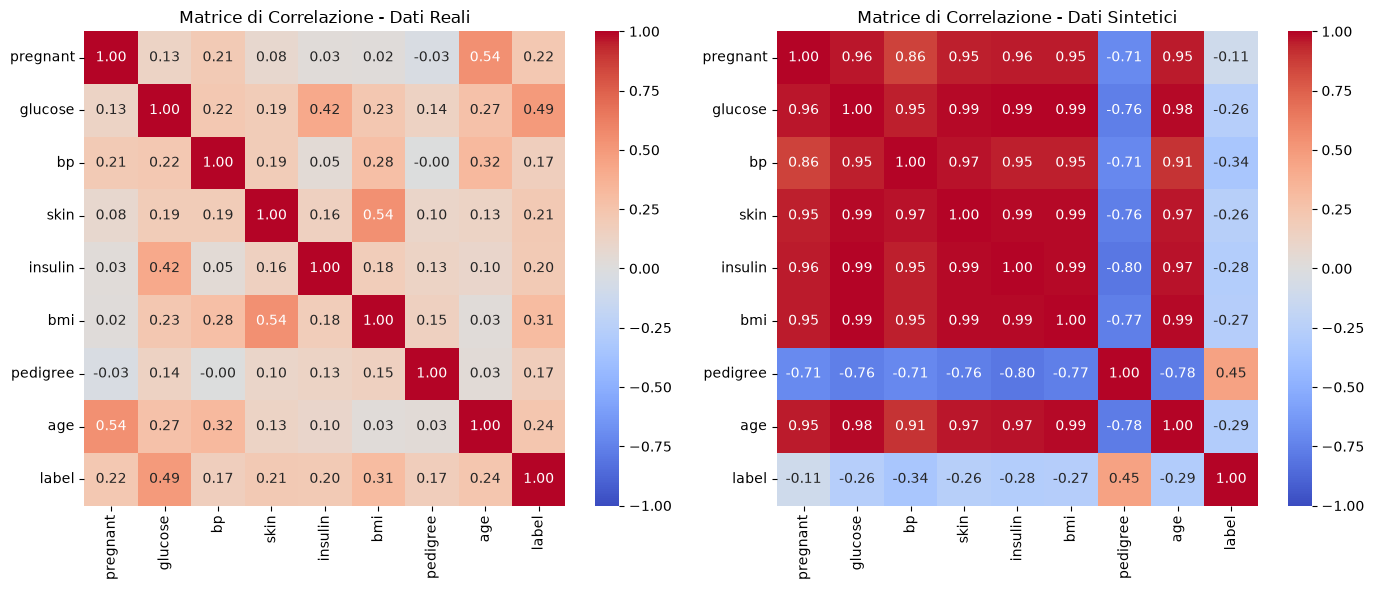

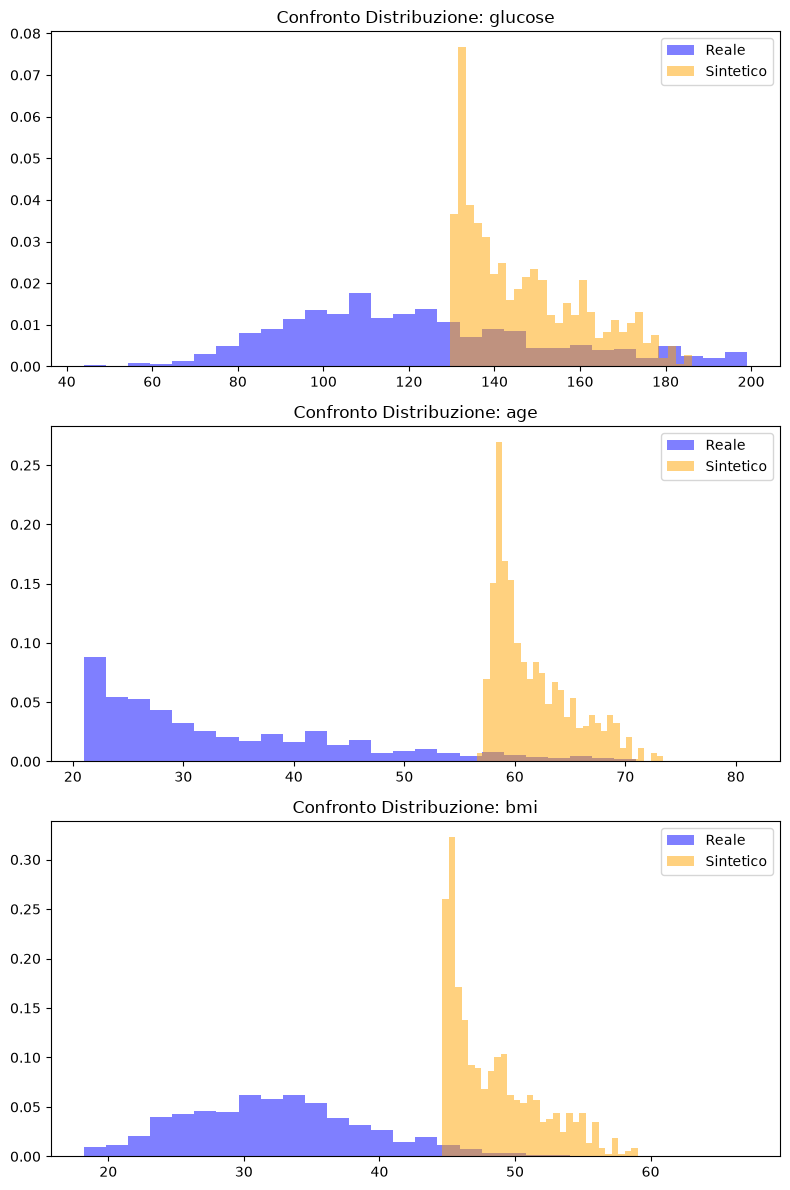

=== PRIVACY CHECK ===
Numero totale di record sintetici generati: 768
Record sintetici identici a record reali (Esatti): 0
Nessun record sintetico è un clone esatto di quelli reali


C:\Users\chian\AppData\Local\Temp\ipykernel_38048\1093133731.py:41: UserWarning: You are merging on int and float columns where the float values are not equal to their int representation.
  matches = pd.merge(synthetic_rounded, real_rounded, how='inner', on=col_names)


In [31]:
# Denormalizzazione dati reali
synthetic_original_array = scaler.inverse_transform(synthetic_df.values)
synthetic_original_scale = pd.DataFrame(synthetic_original_array, columns=col_names)

# Arrotondamento del valore generato con il layer sigmoide per ottenere  
synthetic_original_scale['label'] = synthetic_original_scale['label'].round().clip(0, 1).astype(int)


# 1. Heatmap per confronto
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.heatmap(df[col_names].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[0], vmin=-1, vmax=1)
axes[0].set_title("Matrice di Correlazione - Dati Reali")

sns.heatmap(synthetic_original_scale[col_names].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1], vmin=-1, vmax=1)
axes[1].set_title("Matrice di Correlazione - Dati Sintetici")

plt.tight_layout()
plt.show()


# 2. Confronto tra istogrammi (distribuzioni)
key_features = ['glucose', 'age', 'bmi']

fig, axes = plt.subplots(len(key_features), 1, figsize=(8, 4 * len(key_features)))

for i, col in enumerate(key_features):
    axes[i].hist(df[col], bins=30, alpha=0.5, label='Reale', color='blue', density=True)
    axes[i].hist(synthetic_original_scale[col], bins=30, alpha=0.5, label='Sintetico', color='orange', density=True)
    axes[i].set_title(f"Confronto Distribuzione: {col}")
    axes[i].legend()

plt.tight_layout()
plt.show()


# 3. Privacy Check
real_rounded = df.round(2)
synthetic_rounded = synthetic_original_scale.round(2)

matches = pd.merge(synthetic_rounded, real_rounded, how='inner', on=col_names)
exact_duplicates_count = len(matches)

print(f"=== PRIVACY CHECK ===")
print(f"Numero totale di record sintetici generati: {len(synthetic_rounded)}")
print(f"Record sintetici identici a record reali (Esatti): {exact_duplicates_count}")

if exact_duplicates_count == 0:
    print("Nessun record sintetico è un clone esatto di quelli reali")
else:
    print("Attenzione: presenti alcuni record duplicati")